# Laboratorio 13: Árboles de decisión (CART)

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_13_Desicion_Tree.ipynb`

Se conserva el notebook del enunciado en su orden. Primero se revisa su ejemplo y se implementa el
algoritmo que describe, y después van los siete puntos del laboratorio con Iris.

Las celdas propias empiezan con `# [Añadido]`. La primera adelanta las importaciones que necesita la
figura del enunciado, porque el original las hace varias celdas más abajo. Se omiten una celda vacía y el
botón "Open in Colab", que abre el notebook original del profesor.


#Algoritmo CART (classification and regresion tree)

Se busca entrenar un modelo para categorizar la información encontrando la frontera de desición, permite tener una mejor interpretabilidad que las redes neuronales dado que se puede tener una represetancion grafica del proceso de desiscion secuencial.

- ref https://www.youtube.com/watch?v=kqaLlte6P6o&ab_channel=CodificandoBits
- Hand on Machine leargning 




Dado un conjunto de caracteristicas se establece una condición que realiza 
una particion binaria de los datos a clasificar repitiendo hasta encontrar 
particiones lo más homogenea posible.




In [1]:
# [Añadido]
# La figura del enunciado usa estas funciones antes de la celda donde las importa
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

SEED = 42

Text(0, 0.5, '$X_2$')

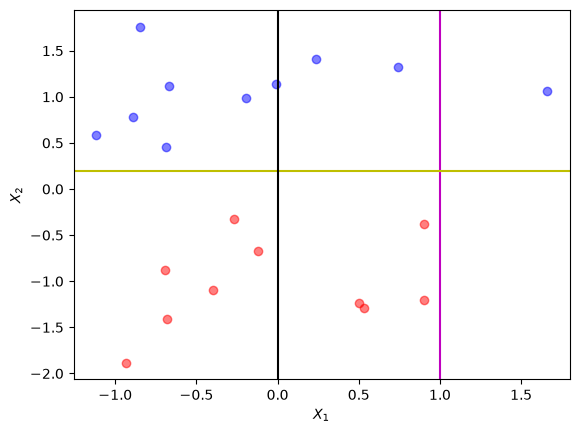

In [2]:
X0, y0 = make_classification(n_samples=20,
    n_features=2, n_redundant=0, n_informative=1, random_state=1, 
    n_clusters_per_class=1)

x=np.arange(-2, 3,1)
x_,y_ = np.meshgrid(x,x)

fig, ax = plt.subplots()
ax.plot(X0[:,0][y0==0],X0[:,1][y0==0],"ro", alpha=0.5)
ax.plot(X0[:,0][y0==1],X0[:,1][y0==1],"bo", alpha=0.5)
#ax.plot(x_,y_,"k.")

ax.axvline(x = 1, color = 'm', label="x1<=1")
ax.axhline(y = 0.2, color = 'y', label="x2<0.2")
ax.axvline(x = 0.0, color = 'k', label="x2<0.2")
#plt.legend(loc=3)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")


- Gini index


$G = 1 - (PC_1)^2 - (PC_2)^2$

$PC_1$: Probablidad categoria 1 

$PC_2$: Probablidad categoria 2 

Si :

- $G=0$ nodos puros, datos que pertenecen a una sola categoría

- Gini > 0 son nodos con impurezas, con mas de una categoría


La partición purpura  y amarilla del gráfico anterior representan nodos puros.

Mientras que la linea negra define:

- 7 puntos son de color azul.

- 6 puntos de color rojo.

$G = 1 - (7/13)^{2} - (6/13)^{2}$

mientrás que la ponderacion viene dada por:

$m = (7/20+7/20)=7/10$



No:

$G=1-(3/7)^{2}-(4/7)^{2}$
m = (3/20+4/20)


La funcion de coste, asocida al nodo padre:

$J(k, t_k) = \frac{m_{left}}{m} G_{left} + \frac{m_{right}}{m} G_{right} $



# Algoritmo
1. Calcular todos los posibles condiciones. 
2. Calcular los indices de Gini.
3. Encontrar la funcion de coste 
4. Escoger la menor funcion de coste 
5. Repetir.


### Revisión del ejemplo del enunciado

Se calculan conteos, pesos, Gini y coste de las tres líneas de la figura.

In [3]:
# [Añadido]
def gini(y):
    if len(y) == 0:
        return 0.0
    _, c = np.unique(y, return_counts=True)
    return 1 - np.sum((c / len(y)) ** 2)


def coste(X, y, k, t):
    izq = X[:, k] <= t
    return izq.mean() * gini(y[izq]) + (~izq).mean() * gini(y[~izq])


print("y = 0 se dibuja en rojo, y = 1 en azul | totales:", np.bincount(y0))
for nombre, k, t in (("negra    x1 <= 0.0", 0, 0.0), ("púrpura  x1 <= 1.0", 0, 1.0), ("amarilla x2 <= 0.2", 1, 0.2)):
    izq = X0[:, k] <= t
    print(f"\n{nombre}   J = {coste(X0, y0, k, t):.4f}")
    for rama, sel in (("sí", izq), ("no", ~izq)):
        rojos, azules = np.bincount(y0[sel], minlength=2)
        print(f"   {rama}: rojos {rojos:2d}, azules {azules:2d}, peso {sel.sum():2d}/20, G = {gini(y0[sel]):.4f}")

print("\npesos que escribe el enunciado para la negra:", (7 + 7) / 20, "+", (3 + 4) / 20, "=", (7 + 7 + 3 + 4) / 20)

y = 0 se dibuja en rojo, y = 1 en azul | totales: [10 10]

negra    x1 <= 0.0   J = 0.4945
   sí: rojos  6, azules  7, peso 13/20, G = 0.4970
   no: rojos  4, azules  3, peso  7/20, G = 0.4898

púrpura  x1 <= 1.0   J = 0.4737
   sí: rojos 10, azules  9, peso 19/20, G = 0.4986
   no: rojos  0, azules  1, peso  1/20, G = 0.0000

amarilla x2 <= 0.2   J = 0.0000
   sí: rojos 10, azules  0, peso 10/20, G = 0.0000
   no: rojos  0, azules 10, peso 10/20, G = 0.0000

pesos que escribe el enunciado para la negra: 0.7 + 0.35 = 1.05


Ahora se aplican los cinco pasos del algoritmo del enunciado: probar todos los cortes, calcular su Gini y
su coste, quedarse con el menor y repetir.

In [4]:
# [Añadido]
def mejor_corte(X, y):
    """Pasos 1 a 4 del algoritmo. Devuelve el coste mínimo y todos los cortes que lo logran."""
    candidatos = []
    for k in range(X.shape[1]):
        valores = np.unique(X[:, k])
        for t in (valores[:-1] + valores[1:]) / 2:      # puntos medios entre valores consecutivos
            candidatos.append((coste(X, y, k, t), k, t))
    minimo = min(c[0] for c in candidatos)
    return minimo, [(k, t) for J, k, t in candidatos if np.isclose(J, minimo)], len(candidatos)


def cart(X, y):
    """Paso 5: repite el corte en cada rama hasta que los nodos sean puros."""
    clase = np.bincount(y).argmax()
    if gini(y) == 0 or all(len(np.unique(c)) == 1 for c in X.T):
        return {"clase": clase}
    _, cortes, _ = mejor_corte(X, y)
    k, t = cortes[0]                                    # si hay empate, el primero
    izq = X[:, k] <= t
    return {"k": k, "t": t, "si": cart(X[izq], y[izq]), "no": cart(X[~izq], y[~izq])}


def predecir_cart(arbol, X):
    salida = []
    for x in X:
        nodo = arbol
        while "clase" not in nodo:
            nodo = nodo["si"] if x[nodo["k"]] <= nodo["t"] else nodo["no"]
        salida.append(nodo["clase"])
    return np.array(salida)


J0, cortes0, total0 = mejor_corte(X0, y0)
print(f"{total0} cortes posibles | J mínimo = {J0}")
for k, t in cortes0:
    print(f"   x{k + 1} <= {t:.4f}")
print("exactitud del árbol propio en los 20 puntos:", np.mean(predecir_cart(cart(X0, y0), X0) == y0))

38 cortes posibles | J mínimo = 0.0
   x2 <= 0.0651
exactitud del árbol propio en los 20 puntos: 1.0


**Qué coincide con el enunciado y qué no.**

- Los conteos de la línea negra son correctos: 7 azules y 6 rojos a un lado ($G=0.4970$), 3 y 4 al otro
  ($G=0.4898$).
- El peso del lado izquierdo tiene una errata. Dice $(7/20+7/20)=7/10$ y debe ser $(7+6)/20=13/20$. Con
  los valores escritos los pesos suman 1.05 en lugar de 1. El coste correcto es $J=0.4945$.
- Solo la línea amarilla separa dos nodos puros ($J=0$). La púrpura deja puro un único punto, y su otro
  nodo tiene 10 rojos y 9 azules ($J=0.4737$).
- La etiqueta de la línea negra en el código está equivocada: dice `x2<0.2` y es $x_1\le0$.

Entre los 38 cortes posibles el algoritmo elige $x_2\le0.0651$, que separa los mismos puntos que la línea
amarilla. Cualquier umbral dentro de ese hueco da el mismo coste, y CART toma el punto medio. Con ese solo
corte clasifica bien los 20 puntos.

# Laboratorio

1. Importar iris dataset 
2. Generar una intuición respecto a iris dataset. Ver laboratorio anterior.
3. Dividir el *dataset* empleanto el metodo train_test_split de sklearn
4. Dentro de sklearn, aplicar el algoritmo DecisionTreeClassifier.
5. Para el clasificador analice el gráfico de desición:

```

https://scikit-learn.org/stable/modules/generated/sklearn.tree.export_graphviz.html

  fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=300)
  graph=tree.plot_tree(clf,class_names = iris.target_names,\
                feature_names = iris.feature_names,\
                impurity=False, filled=True,rounded=True )

```

6. Características importantes.

```
clf.feature_importances_
caract = iris.data.shape[1]
plt.barh(range(caract), clf.feature_importances_)
plt.yticks(np.arange(caract),iris.feature_names)
plt.xlabel('Importancia de las características')
plt.ylabel('Características')
plt.show()
```

7. Fronteras de desición.



```
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
# Parameters
n_classes = 3
plot_colors = "bry"
plot_step = 0.02

# Load data
iris = load_iris()

for pairidx, pair in enumerate([[0, 1], [0, 2], [0, 3],
                                [1, 2], [1, 3], [2, 3]]):
    # We only take the two corresponding features
    X = iris.data[:, pair]
    y = iris.target

    # Shuffle
    idx = np.arange(X.shape[0])
    np.random.seed(13)
    np.random.shuffle(idx)
    X = X[idx]
    y = y[idx]

    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std

    # Train
    clf = DecisionTreeClassifier().fit(X, y)

    # Plot the decision boundary
    plt.subplot(2, 3, pairidx + 1)
  
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=plt.cm.Paired)

    plt.xlabel(iris.feature_names[pair[0]])
    plt.ylabel(iris.feature_names[pair[1]])
    plt.axis("tight")

    # Plot the training points
    for i, color in zip(range(n_classes), plot_colors):
        idx = np.where(y == i)
        plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
                    cmap=plt.cm.Paired)

    plt.axis("tight")

plt.suptitle("Decision surface of a decision tree using paired features")
plt.legend()
plt.show()
```


### Punto 1. Importar Iris

> 1. Importar iris dataset

In [5]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pylab as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
import graphviz
#from sklearn.tree import export_graphviz
import matplotlib.pyplot as plt
import numpy as np
from sklearn import tree


In [6]:
# [Añadido]
import pandas as pd
import seaborn as sns
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, classification_report

iris = load_iris()
print("X:", iris.data.shape, "| y:", iris.target.shape)
print("características:", iris.feature_names)
print("clases:", iris.target_names.tolist(), "| ejemplos por clase:", np.bincount(iris.target))

X: (150, 4) | y: (150,)
características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
clases: ['setosa', 'versicolor', 'virginica'] | ejemplos por clase: [50 50 50]


Son 150 flores, 50 de cada especie, con cuatro medidas en centímetros. Al estar balanceado, la exactitud
sirve como métrica y la referencia de predecir una sola clase es $1/3$.

### Punto 2. Intuición sobre los datos

> 2. Generar una intuición respecto a iris dataset. Ver laboratorio anterior.

In [7]:
# [Añadido]
COL = ["sepalo_largo", "sepalo_ancho", "petalo_largo", "petalo_ancho"]     # todas en cm
df = pd.DataFrame(iris.data, columns=COL)
df["especie"] = iris.target_names[iris.target]
print("faltantes:", df.isna().sum().sum(), "| filas repetidas:", df.duplicated().sum(),
      "| índices del grupo repetido:", df[df.duplicated(keep=False)].index.tolist())
print("\nMínimo, media y máximo por especie (cm):")
print(df.groupby("especie")[COL].agg(["min", "mean", "max"]).round(2).T.to_string())
print("\nCorrelación (Pearson):")
print(df[COL].corr().round(3).to_string())

faltantes: 0 | filas repetidas: 1 | índices del grupo repetido: [101, 142]

Mínimo, media y máximo por especie (cm):
especie            setosa  versicolor  virginica
sepalo_largo min     4.30        4.90       4.90
             mean    5.01        5.94       6.59
             max     5.80        7.00       7.90
sepalo_ancho min     2.30        2.00       2.20
             mean    3.43        2.77       2.97
             max     4.40        3.40       3.80
petalo_largo min     1.00        3.00       4.50
             mean    1.46        4.26       5.55
             max     1.90        5.10       6.90
petalo_ancho min     0.10        1.00       1.40
             mean    0.25        1.33       2.03
             max     0.60        1.80       2.50

Correlación (Pearson):
              sepalo_largo  sepalo_ancho  petalo_largo  petalo_ancho
sepalo_largo         1.000        -0.118         0.872         0.818
sepalo_ancho        -0.118         1.000        -0.428        -0.366
petalo_largo   

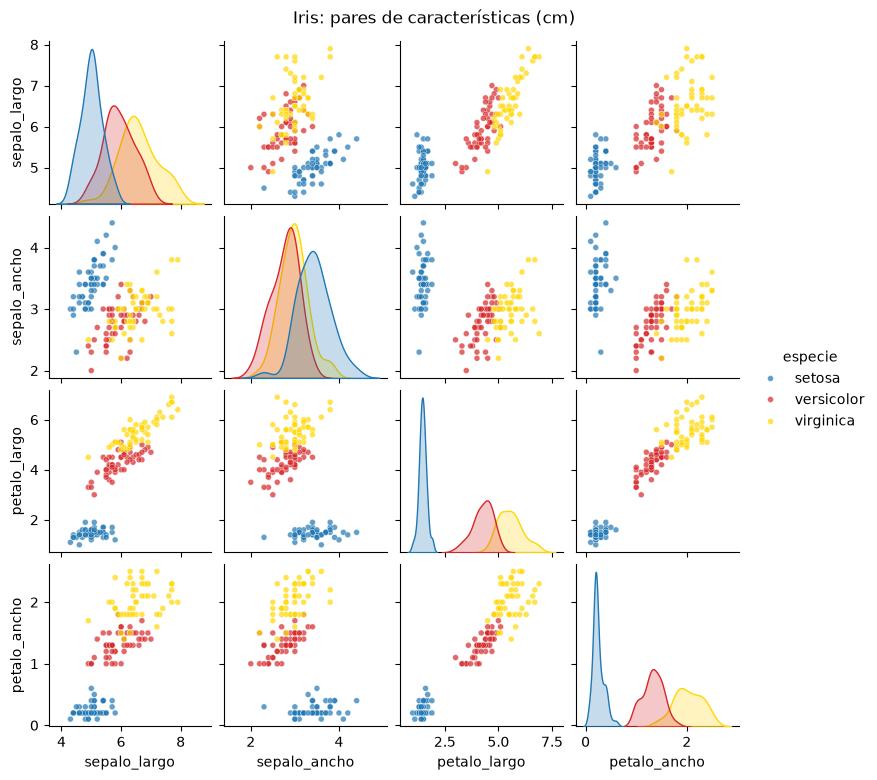

In [8]:
# [Añadido]
COLORES = ["tab:blue", "tab:red", "gold"]
g = sns.pairplot(df, hue="especie", palette=COLORES, height=1.9, plot_kws={"s": 18, "alpha": 0.7})
g.figure.suptitle("Iris: pares de características (cm)", y=1.02)
plt.show()

In [9]:
# [Añadido]
# ¿Cuánto logra un solo corte con cada característica? (150 flores)
for k, nombre in enumerate(COL):
    J, cortes, _ = mejor_corte(iris.data[:, [k]], iris.target)
    print(f"{nombre:13s} mejor corte <= {cortes[0][1]:.2f}   J = {J:.4f}")
print(f"Gini sin cortar = {gini(iris.target):.4f}")

for k in (2, 3):
    otras = iris.data[iris.target > 0, k]
    print(f"{COL[k]}: setosa llega hasta {iris.data[iris.target == 0, k].max()}, las otras empiezan en {otras.min()}")
a, b = iris.data[iris.target == 1], iris.data[iris.target == 2]
for k in (2, 3):
    bajo, alto = b[:, k].min(), a[:, k].max()
    en_rango = [int(np.sum((z[:, k] >= bajo) & (z[:, k] <= alto))) for z in (a, b)]
    print(f"{COL[k]}: versicolor y virginica se cruzan entre {bajo} y {alto} (flores {en_rango})")

sepalo_largo  mejor corte <= 5.45   J = 0.4389
sepalo_ancho  mejor corte <= 3.35   J = 0.5397
petalo_largo  mejor corte <= 2.45   J = 0.3333
petalo_ancho  mejor corte <= 0.80   J = 0.3333
Gini sin cortar = 0.6667
petalo_largo: setosa llega hasta 1.9, las otras empiezan en 3.0
petalo_ancho: setosa llega hasta 0.6, las otras empiezan en 1.0
petalo_largo: versicolor y virginica se cruzan entre 4.5 y 5.1 (flores [21, 16])
petalo_ancho: versicolor y virginica se cruzan entre 1.4 y 1.8 (flores [22, 16])


**Lo que se espera del árbol antes de entrenarlo.**

- No hay faltantes. Hay una fila repetida (índices 101 y 142).
- Setosa se separa con un solo corte en el pétalo: su largo llega hasta 1.9 cm y el de las otras empieza
  en 3.0, su ancho hasta 0.6 y las otras desde 1.0. Cualquiera de los dos cortes baja el Gini de 0.6667 a
  0.3333, así que habrá empate en la raíz.
- La dificultad está entre versicolor y virginica, que se cruzan de 4.5 a 5.1 cm de largo y de 1.4 a 1.8
  cm de ancho de pétalo.
- El sépalo separa peor ($J=0.4389$ y $J=0.5397$ en su mejor corte).
- Largo y ancho del pétalo tienen correlación 0.963. Son casi intercambiables, y eso va a afectar la
  interpretación de las importancias.

### Punto 3. Partición

> 3. Dividir el *dataset* empleanto el metodo train_test_split de sklearn

Se reserva 30 % para prueba, estratificado por especie.

In [10]:
# [Añadido]
indices = np.arange(len(iris.target))
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    iris.data, iris.target, indices, test_size=0.30, stratify=iris.target, random_state=SEED)
print("entrenamiento:", X_train.shape, np.bincount(y_train), "| prueba:", X_test.shape, np.bincount(y_test))
for i in df[df.duplicated(keep=False)].index:
    print(f"fila repetida {i}: quedó en", "entrenamiento" if i in idx_train else "prueba")

entrenamiento: (105, 4) [35 35 35] | prueba: (45, 4) [15 15 15]
fila repetida 101: quedó en entrenamiento
fila repetida 142: quedó en entrenamiento


Quedan 105 flores para entrenar (35 por especie) y 45 de prueba (15 por especie). Las dos copias de la
fila repetida cayeron en entrenamiento, de modo que no se filtran a la prueba. La prueba no interviene en
la elección del modelo.

### Punto 4. `DecisionTreeClassifier`

> 4. Dentro de sklearn, aplicar el algoritmo DecisionTreeClassifier.

In [11]:
# [Añadido]
completo = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print(f"árbol por defecto: profundidad {completo.get_depth()}, hojas {completo.get_n_leaves()}, "
      f"exactitud en entrenamiento {completo.score(X_train, y_train):.3f}")

árbol por defecto: profundidad 5, hojas 8, exactitud en entrenamiento 1.000


Sin restricciones el árbol crece hasta no equivocarse en entrenamiento. La profundidad se elige con
validación cruzada estratificada (5 pliegues, 20 repeticiones) usando solo entrenamiento. La prueba se
mira después.

max_depth  entrenamiento  validación  desv.  hojas
        1         0.6667      0.6667 0.0000      2
        2         0.9714      0.9376 0.0348      3
        3         0.9810      0.9571 0.0390      5
        4         0.9905      0.9452 0.0389      7
        5         1.0000      0.9452 0.0389      8
     None         1.0000      0.9452 0.0389      8
max_depth elegida: 3


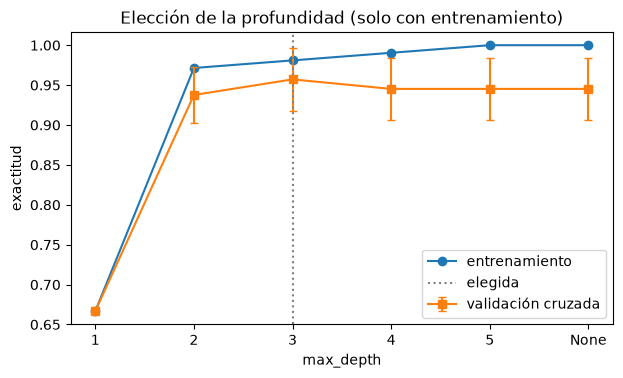

In [12]:
# [Añadido]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
profundidades = [1, 2, 3, 4, 5, None]
filas = []
for prof in profundidades:
    modelo = DecisionTreeClassifier(max_depth=prof, random_state=SEED)
    val = cross_val_score(modelo, X_train, y_train, cv=cv)
    modelo.fit(X_train, y_train)
    filas.append((str(prof), modelo.score(X_train, y_train), val.mean(), val.std(), modelo.get_n_leaves()))
tabla = pd.DataFrame(filas, columns=["max_depth", "entrenamiento", "validación", "desv.", "hojas"])
print(tabla.round(4).to_string(index=False))

mejor = tabla["validación"].round(6).idxmax()     # ante un empate, el árbol menos profundo
PROF = profundidades[mejor]
print("max_depth elegida:", PROF)

x_pos = np.arange(len(tabla))
plt.figure(figsize=(7, 3.8))
plt.plot(x_pos, tabla["entrenamiento"], "o-", label="entrenamiento")
plt.errorbar(x_pos, tabla["validación"], yerr=tabla["desv."], fmt="s-", capsize=3, label="validación cruzada")
plt.axvline(mejor, color="gray", ls=":", label="elegida")
plt.xticks(x_pos, tabla["max_depth"])
plt.xlabel("max_depth")
plt.ylabel("exactitud")
plt.title("Elección de la profundidad (solo con entrenamiento)")
plt.legend()
plt.show()

In [13]:
# [Añadido]
clf = DecisionTreeClassifier(max_depth=PROF, random_state=SEED).fit(X_train, y_train)
pred = clf.predict(X_test)
mayoritaria = np.bincount(y_train).argmax()
print(f"referencia (una sola clase): {np.mean(y_test == mayoritaria):.3f}")
print(f"árbol por defecto:           {completo.score(X_test, y_test):.3f}")
print(f"árbol elegido:               {clf.score(X_test, y_test):.3f} ({np.sum(pred == y_test)}/{len(y_test)})")
print("\nMatriz de confusión (filas = real, columnas = predicho):")
print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred, target_names=iris.target_names, digits=3))

referencia (una sola clase): 0.333
árbol por defecto:           0.933
árbol elegido:               0.978 (44/45)

Matriz de confusión (filas = real, columnas = predicho):
[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.933     0.966        15
   virginica      0.938     1.000     0.968        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



In [14]:
# [Añadido]
# Qué tanto depende el resultado de la partición
PARTICIONES = 500
acc = np.empty((PARTICIONES, 2))
for k in range(PARTICIONES):
    a, b, c, e = train_test_split(iris.data, iris.target, test_size=0.30, stratify=iris.target, random_state=k)
    for j, prof in enumerate((PROF, None)):
        acc[k, j] = DecisionTreeClassifier(max_depth=prof, random_state=SEED).fit(a, c).score(b, e)
print(f"particiones probadas: {PARTICIONES}")
for j, nombre in enumerate(("elegido", "por defecto")):
    p5, p50, p95 = np.percentile(acc[:, j], [5, 50, 95])
    print(f"{nombre:12s} media {acc[:, j].mean():.3f} | percentiles 5, 50, 95: {p5:.3f}, {p50:.3f}, {p95:.3f}")
print(f"esta partición da {clf.score(X_test, y_test):.3f}: "
      f"{np.mean(acc[:, 0] < clf.score(X_test, y_test) - 1e-9):.1%} de las particiones quedan por debajo")

particiones probadas: 500
elegido      media 0.944 | percentiles 5, 50, 95: 0.889, 0.956, 0.978
por defecto  media 0.945 | percentiles 5, 50, 95: 0.889, 0.956, 0.978
esta partición da 0.978: 72.4% de las particiones quedan por debajo


**Resultado.**

- Con profundidad 1 hay dos hojas para tres especies, y la exactitud no pasa de 0.6667.
- La mejor validación está en profundidad 3: 0.9571, contra 0.9452 del árbol completo. Este llega a 1.000
  en entrenamiento con 8 hojas, y lo que gana allí no se traslada a validación.
- En prueba el árbol elegido acierta 44 de 45 (0.978) y el completo queda en 0.933. El único error es una
  versicolor clasificada como virginica.

Esa diferencia no debe sobreinterpretarse. En validación es menor que la desviación entre pliegues
(0.039), y al repetir la partición 500 veces los dos árboles empatan (0.944 y 0.945 en promedio). El 0.978
viene de una partición favorable: el 72.4 % de las particiones da menos. Ante datos
nuevos lo razonable es esperar alrededor de 0.94. La razón para preferir el árbol de profundidad 3 es que es
más simple con el mismo desempeño.

### Punto 5. Gráfico de decisión

> 5. Para el clasificador analice el gráfico de desición:

Se ejecuta el código sugerido. Como oculta la impureza (`impurity=False`), se grafica otra vez con ella.

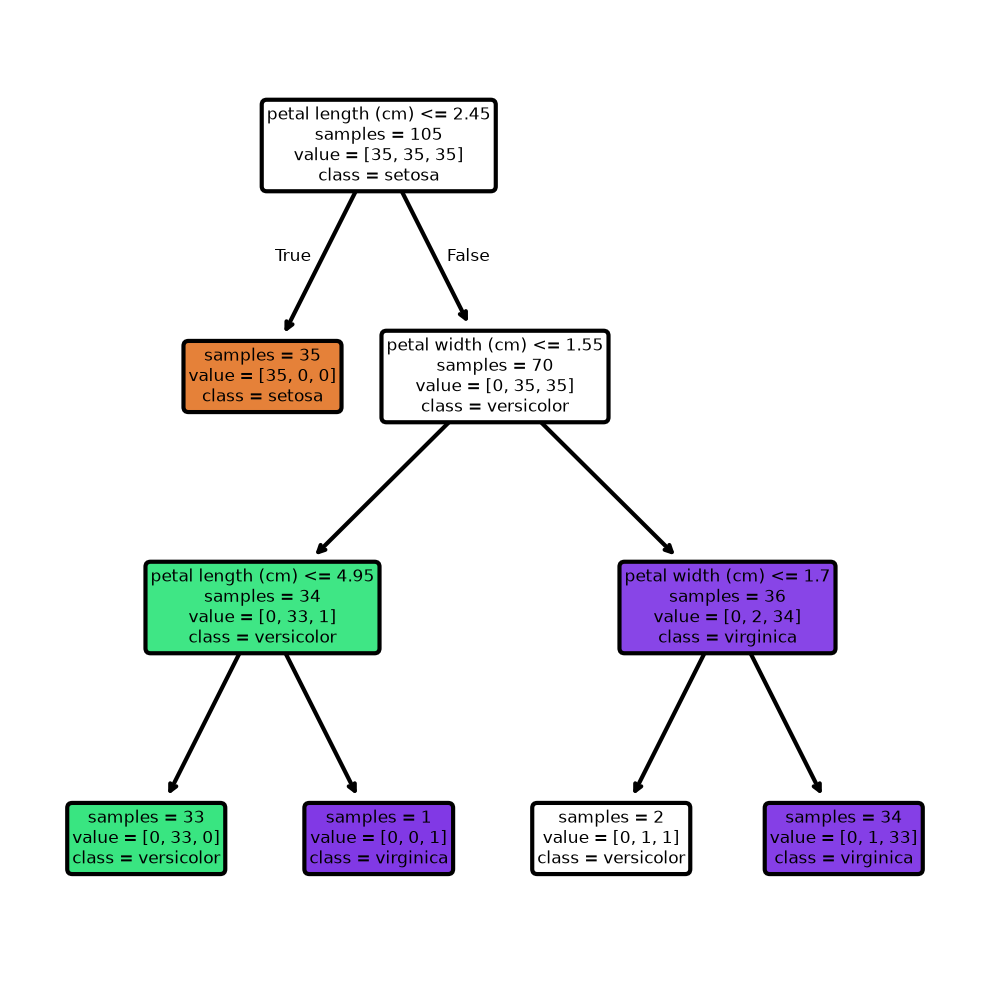

In [15]:
# [Añadido]
# Código sugerido en el enunciado
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 4), dpi=300)
graph = tree.plot_tree(clf, class_names=iris.target_names,
                       feature_names=iris.feature_names,
                       impurity=False, filled=True, rounded=True)
plt.show()

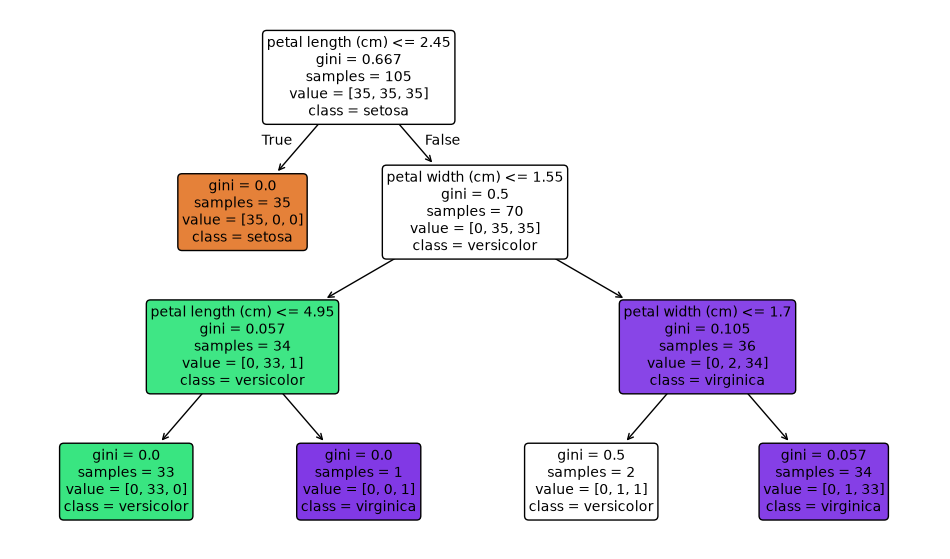

|--- petal length (cm) <= 2.45
|   |--- weights: [35.00, 0.00, 0.00] class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- weights: [0.00, 33.00, 0.00] class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- weights: [0.00, 0.00, 1.00] class: virginica
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- weights: [0.00, 1.00, 1.00] class: versicolor
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- weights: [0.00, 1.00, 33.00] class: virginica



In [16]:
# [Añadido]
# El mismo árbol con la impureza, que es lo que minimiza el algoritmo
plt.figure(figsize=(12, 7))
tree.plot_tree(clf, class_names=iris.target_names, feature_names=iris.feature_names,
               impurity=True, filled=True, rounded=True, fontsize=10)
plt.show()
print(tree.export_text(clf, feature_names=list(iris.feature_names),
                       class_names=iris.target_names.tolist(), show_weights=True))

In [17]:
# [Añadido]
# La raíz de scikit-learn contra la búsqueda propia
J_raiz, cortes, total = mejor_corte(X_train, y_train)
t_ = clf.tree_
print(f"{total} cortes posibles en la raíz | J mínimo = {J_raiz:.4f}, lo logran:")
for k, t in cortes:
    print(f"   {COL[k]} <= {t:.2f}")
print(f"scikit-learn eligió {COL[t_.feature[0]]} <= {t_.threshold[0]:.2f}, "
      f"J = {coste(X_train, y_train, t_.feature[0], t_.threshold[0]):.4f}")

print("Gini de los nodos internos:", t_.impurity[t_.children_left != -1].round(3))

# Recorrido de cada flor mal clasificada en prueba
for q in np.where(pred != y_test)[0]:
    print(f"\nflor {idx_test[q]} {X_test[q]}: real {iris.target_names[y_test[q]]}, "
          f"predicha {iris.target_names[pred[q]]}")
    for nodo in clf.decision_path(X_test[[q]]).indices:
        if t_.children_left[nodo] == -1:
            print(f"   hoja con {np.rint(t_.value[nodo][0] * t_.n_node_samples[nodo]).astype(int)} flores de entrenamiento")
        else:
            k, t = t_.feature[nodo], t_.threshold[nodo]
            x_32 = np.float32(X_test[q, k])          # scikit-learn compara en float32
            print(f"   {COL[k]} = {float(x_32):.9f} {'<=' if x_32 <= t else '>'} {t:.9f}")

109 cortes posibles en la raíz | J mínimo = 0.3333, lo logran:
   petalo_largo <= 2.45
   petalo_ancho <= 0.70
scikit-learn eligió petalo_largo <= 2.45, J = 0.3333
Gini de los nodos internos: [0.667 0.5   0.057 0.105]

flor 77 [6.7 3.  5.  1.7]: real versicolor, predicha virginica
   petalo_largo = 5.000000000 > 2.449999988
   petalo_ancho = 1.700000048 > 1.550000012
   petalo_ancho = 1.700000048 > 1.699999988
   hoja con [ 0  1 33] flores de entrenamiento


In [18]:
# [Añadido]
# El error cae sobre un umbral. Como iris se midió con un decimal, en milímetros todo es entero exacto
mm_train, mm_test = np.rint(X_train * 10), np.rint(X_test * 10)
clf_mm = DecisionTreeClassifier(max_depth=PROF, random_state=SEED).fit(mm_train, y_train)
interno = t_.children_left != -1
print("mismas características en cada nodo:", np.array_equal(clf_mm.tree_.feature, t_.feature))
print("umbrales en cm:", t_.threshold[interno])
print("umbrales en mm:", clf_mm.tree_.threshold[interno])
sobre = []
for q in range(len(y_test)):
    camino = [nodo for nodo in clf_mm.decision_path(mm_test[[q]]).indices if interno[nodo]]
    if any(mm_test[q, t_.feature[nodo]] == clf_mm.tree_.threshold[nodo] for nodo in camino):
        sobre.append(int(idx_test[q]))
print("flores de prueba que caen justo sobre un umbral de su recorrido:",
      {i: str(iris.target_names[iris.target[i]]) for i in sobre})
pred_mm = clf_mm.predict(mm_test)
print(f"aciertos en prueba: en cm {np.sum(pred == y_test)}/45 | en mm {np.sum(pred_mm == y_test)}/45")
print("flores falladas: en cm", idx_test[pred != y_test], "| en mm", idx_test[pred_mm != y_test])

mismas características en cada nodo: True
umbrales en cm: [2.44999999 1.55000001 4.95000005 1.69999999]
umbrales en mm: [24.5 15.5 49.5 17. ]
flores de prueba que caen justo sobre un umbral de su recorrido: {77: 'versicolor', 106: 'virginica'}
aciertos en prueba: en cm 44/45 | en mm 44/45
flores falladas: en cm [77] | en mm [106]


**Lectura del árbol.** En cada nodo, `samples` es cuántas flores llegan, `value` cuántas de cada especie
y `class` la mayoritaria. La intensidad del color indica la pureza.

1. Raíz (Gini 0.667): `petal length <= 2.45` aísla las 35 setosas en una hoja pura. La búsqueda propia
   encuentra ese mismo coste entre 109 cortes y confirma el empate con `petal width <= 0.70`.
2. Segundo nivel (Gini 0.5): `petal width <= 1.55` separa casi todo versicolor de virginica y deja 34 y 36
   flores, con Gini 0.057 y 0.105.
3. Tercer nivel: son correcciones pequeñas. Una hoja tiene una sola flor y otra tiene dos, una de cada
   especie. En esta última la clase versicolor sale de un empate, así que esas reglas tienen poco respaldo.

**El error de prueba cae justo sobre un umbral.** La flor 77 mide 1.7 cm y el último corte es el punto
medio entre 1.6 y 1.8, o sea 1.7. Debería cumplir $\le$, pero en `float32` el umbral quedó en 1.699999988
y la medida en 1.700000048, y se va por la otra rama. Al reentrenar en milímetros, donde el umbral es 17
exacto, el árbol es el mismo y sigue en 44 de 45, porque hay dos flores sobre ese umbral (77 y 106) de
especies distintas: se arregla la 77 y se daña la 106. El número de aciertos no cambia, pero cuál flor se
falla depende del redondeo.

### Punto 6. Características importantes

> 6. Características importantes.

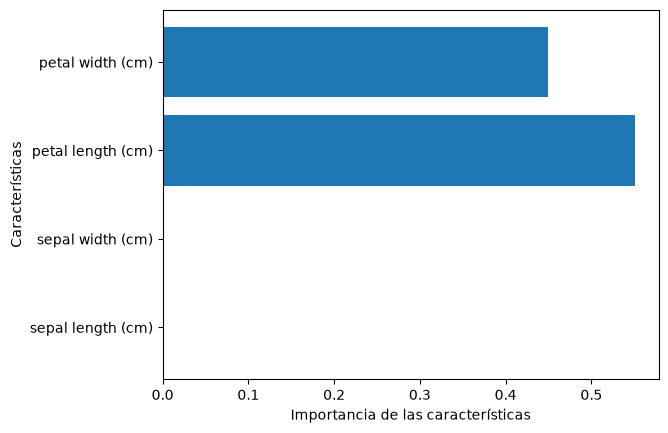

In [19]:
# [Añadido]
# Código sugerido en el enunciado
clf.feature_importances_
caract = iris.data.shape[1]
plt.barh(range(caract), clf.feature_importances_)
plt.yticks(np.arange(caract), iris.feature_names)
plt.xlabel('Importancia de las características')
plt.ylabel('Características')
plt.show()

In [20]:
# [Añadido]
# La importancia es la caída de Gini, ponderada por muestras, acumulada por característica
imp = np.zeros(caract)
for nodo in range(t_.node_count):
    izq, der = t_.children_left[nodo], t_.children_right[nodo]
    if izq == -1:
        continue
    caida = (t_.weighted_n_node_samples[nodo] * t_.impurity[nodo]
             - t_.weighted_n_node_samples[izq] * t_.impurity[izq]
             - t_.weighted_n_node_samples[der] * t_.impurity[der])
    imp[t_.feature[nodo]] += caida
imp /= imp.sum()
print("calculada a mano:", imp.round(4))
print("scikit-learn:    ", clf.feature_importances_.round(4))

# Mismos datos y misma profundidad: solo cambia random_state, que resuelve los empates
semillas = [DecisionTreeClassifier(max_depth=PROF, random_state=k).fit(X_train, y_train) for k in range(500)]
imps = np.array([a.feature_importances_ for a in semillas])
raices = np.array([a.tree_.feature[0] for a in semillas])
print("\nrandom_state de 0 a 499:")
for k, nombre in enumerate(COL):
    print(f"  {nombre:13s} importancia entre {imps[:, k].min():.3f} y {imps[:, k].max():.3f}"
          f" | es la raíz en {np.mean(raices == k):.1%}")
for k in (2, 3):
    rango = imps[raices == k, 2]
    print(f"con raíz en {COL[k]}, la importancia de petalo_largo va de {rango.min():.3f} a {rango.max():.3f}")

calculada a mano: [0.     0.     0.5509 0.4491]
scikit-learn:     [0.     0.     0.5509 0.4491]

random_state de 0 a 499:
  sepalo_largo  importancia entre 0.000 y 0.000 | es la raíz en 0.0%
  sepalo_ancho  importancia entre 0.000 y 0.000 | es la raíz en 0.0%
  petalo_largo  importancia entre 0.029 y 0.563 | es la raíz en 50.6%
  petalo_ancho  importancia entre 0.437 y 0.971 | es la raíz en 49.4%
con raíz en petalo_largo, la importancia de petalo_largo va de 0.551 a 0.563
con raíz en petalo_ancho, la importancia de petalo_largo va de 0.029 a 0.041


In [21]:
# [Añadido]
# Dos contrastes que no dependen de la caída de Gini, ambos sin usar la prueba
perm, raices_cv = [], []
for tr, va in cv.split(X_train, y_train):
    modelo = DecisionTreeClassifier(max_depth=PROF, random_state=SEED).fit(X_train[tr], y_train[tr])
    raices_cv.append(modelo.tree_.feature[0])
    perm.append(permutation_importance(modelo, X_train[va], y_train[va], n_repeats=10,
                                       random_state=SEED).importances_mean)
print(f"árboles de validación con la raíz en petalo_largo: {raices_cv.count(2)}/{len(raices_cv)}")
print("caída de exactitud en validación al permutar:")
for nombre, valor in zip(COL, np.mean(perm, axis=0)):
    print(f"  {nombre:13s} {valor:.3f}")

grupos = {"las cuatro": [0, 1, 2, 3], "sin petalo_largo": [0, 1, 3], "sin petalo_ancho": [0, 1, 2],
          "solo pétalo": [2, 3], "solo sépalo": [0, 1]}
print("\nexactitud en validación al reentrenar con un subconjunto:")
for nombre, cols in grupos.items():
    val = cross_val_score(DecisionTreeClassifier(max_depth=PROF, random_state=SEED), X_train[:, cols], y_train, cv=cv)
    print(f"  {nombre:17s} {val.mean():.3f}")

árboles de validación con la raíz en petalo_largo: 100/100
caída de exactitud en validación al permutar:
  sepalo_largo  0.000
  sepalo_ancho  0.000
  petalo_largo  0.517
  petalo_ancho  0.166

exactitud en validación al reentrenar con un subconjunto:
  las cuatro        0.957
  sin petalo_largo  0.966
  sin petalo_ancho  0.946
  solo pétalo       0.957
  solo sépalo       0.771


**El pétalo concentra toda la importancia: 0.551 el largo y 0.449 el ancho. El sépalo tiene 0.**

La importancia es la reducción de Gini que aporta cada característica, ponderada por las muestras del nodo
y normalizada. El cálculo a mano reproduce `feature_importances_`.

El reparto entre largo y ancho no es una propiedad de las flores:

- Con los mismos datos, cambiar solo `random_state` mueve la importancia del largo entre 0.029 y 0.563.
  La raíz se sortea entre los dos cortes empatados (50.6 % y 49.4 % de las veces): si gana el largo su
  importancia queda entre 0.551 y 0.563, y si gana el ancho, entre 0.029 y 0.041.
- Al permutar, el largo parece más importante (0.517 contra 0.166), pero ese método mide de qué depende
  cada árbol ajustado, y con esta semilla los 100 árboles de validación tienen el largo en la raíz.
- Si se reentrena sin el largo no se pierde nada (0.966 contra 0.957 con las cuatro). El ancho lo
  reemplaza.

Lo que sí es robusto es que importa el pétalo como grupo: solo con él se obtiene 0.957 y solo con el
sépalo 0.771. Una importancia de 0 tampoco significa que el sépalo no tenga información, porque 0.771
está muy por encima de $1/3$. Significa que no agrega nada si el pétalo está disponible.

### Punto 7. Fronteras de decisión

> 7. Fronteras de desición.

Cambios al código sugerido, sin alterar su lógica:

- `random_state` fijo, para que la figura sea reproducible.
- El modelo se llama `clf_par`, para no borrar el `clf` de los puntos anteriores.
- `scatter` no lleva `cmap` (Matplotlib lo ignora con colores fijos y emite un aviso) y lleva borde en
  los puntos.
- Figura más grande y exactitud impresa de cada árbol.

sepalo_largo + sepalo_ancho: exactitud sobre sus 150 puntos 0.927, hojas 47
sepalo_largo + petalo_largo: exactitud sobre sus 150 puntos 0.993, hojas 13
sepalo_largo + petalo_ancho: exactitud sobre sus 150 puntos 0.973, hojas 15
sepalo_ancho + petalo_largo: exactitud sobre sus 150 puntos 0.987, hojas 17
sepalo_ancho + petalo_ancho: exactitud sobre sus 150 puntos 0.980, hojas 16
petalo_largo + petalo_ancho: exactitud sobre sus 150 puntos 0.993, hojas 8


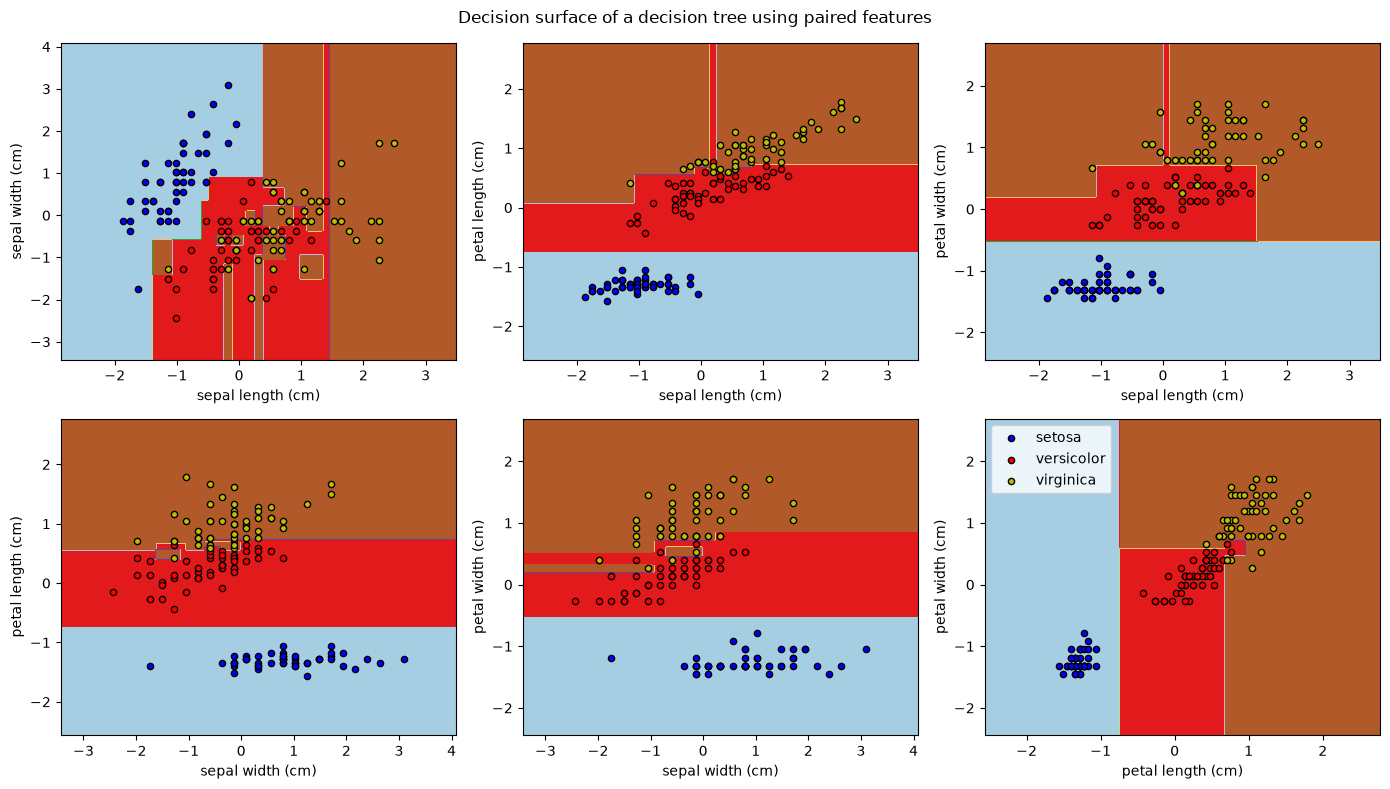

In [22]:
# [Añadido]
# Código sugerido en el enunciado (cambios descritos arriba)
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
# Parameters
n_classes = 3
plot_colors = "bry"
plot_step = 0.02

# Load data
iris = load_iris()
plt.figure(figsize=(14, 8))

for pairidx, pair in enumerate([[0, 1], [0, 2], [0, 3],
                                [1, 2], [1, 3], [2, 3]]):
    # We only take the two corresponding features
    X = iris.data[:, pair]
    y = iris.target

    # Shuffle
    idx = np.arange(X.shape[0])
    np.random.seed(13)
    np.random.shuffle(idx)
    X = X[idx]
    y = y[idx]

    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std

    # Train
    clf_par = DecisionTreeClassifier(random_state=SEED).fit(X, y)

    # Plot the decision boundary
    plt.subplot(2, 3, pairidx + 1)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))

    Z = clf_par.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=plt.cm.Paired)

    plt.xlabel(iris.feature_names[pair[0]])
    plt.ylabel(iris.feature_names[pair[1]])
    plt.axis("tight")

    # Plot the training points
    for i, color in zip(range(n_classes), plot_colors):
        idx = np.where(y == i)
        plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
                    edgecolor="k", s=20)

    plt.axis("tight")
    print(f"{COL[pair[0]]} + {COL[pair[1]]}: exactitud sobre sus 150 puntos {clf_par.score(X, y):.3f}, "
          f"hojas {clf_par.get_n_leaves()}")

plt.suptitle("Decision surface of a decision tree using paired features")
plt.legend()
plt.tight_layout()
plt.show()

Esa figura usa las 150 flores, árboles sin límite y ejes estandarizados (aunque las etiquetas digan cm).
Muestra cómo se ajusta un árbol, pero no cuánto generaliza. Se repite con la profundidad elegida, solo con
entrenamiento y en centímetros.

par                          hojas  entren.  valid.
sepalo_largo + sepalo_ancho      7    0.838   0.771
sepalo_largo + petalo_largo      5    0.962   0.946
sepalo_largo + petalo_ancho      5    0.971   0.966
sepalo_ancho + petalo_largo      5    0.962   0.946
sepalo_ancho + petalo_ancho      5    0.971   0.966
petalo_largo + petalo_ancho      5    0.981   0.957


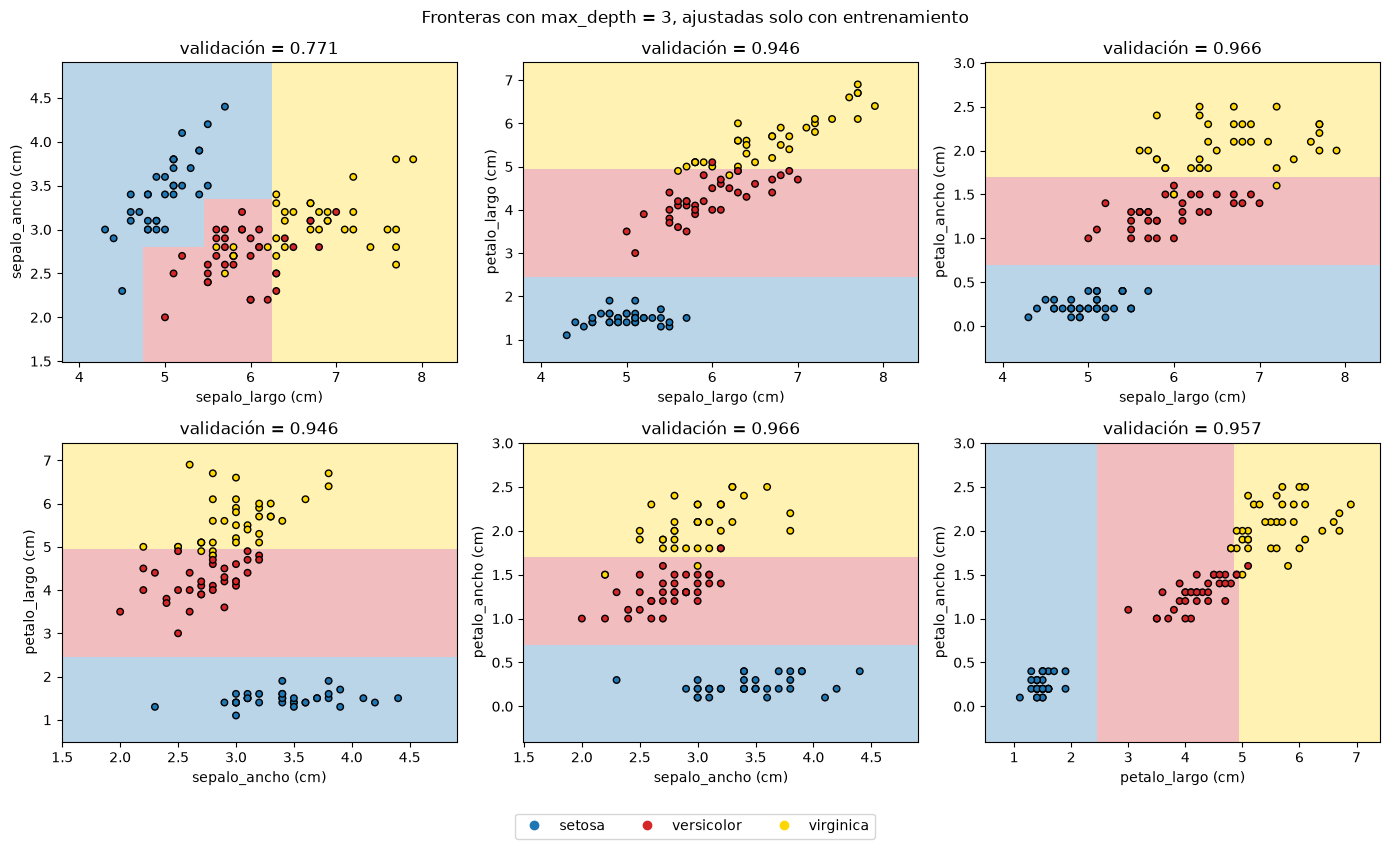

In [23]:
# [Añadido]
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

mapa = ListedColormap(COLORES)
pares = [[0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
print(f"{'par':28s} {'hojas':>5} {'entren.':>8} {'valid.':>7}")
for ax, par in zip(axes.ravel(), pares):
    Xp = X_train[:, par]
    val = cross_val_score(DecisionTreeClassifier(max_depth=PROF, random_state=SEED), Xp, y_train, cv=cv).mean()
    modelo = DecisionTreeClassifier(max_depth=PROF, random_state=SEED).fit(Xp, y_train)
    g1, g2 = [np.linspace(c.min() - 0.5, c.max() + 0.5, 300) for c in iris.data[:, par].T]
    G1, G2 = np.meshgrid(g1, g2)
    ax.pcolormesh(G1, G2, modelo.predict(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape),
                  cmap=mapa, vmin=0, vmax=2, alpha=0.3, shading="auto")
    ax.scatter(*Xp.T, c=y_train, cmap=mapa, vmin=0, vmax=2, edgecolor="k", s=22)
    ax.set(xlabel=f"{COL[par[0]]} (cm)", ylabel=f"{COL[par[1]]} (cm)", title=f"validación = {val:.3f}")
    print(f"{' + '.join(COL[k] for k in par):28s} {modelo.get_n_leaves():5d} "
          f"{modelo.score(Xp, y_train):8.3f} {val:7.3f}")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=e)
                    for c, e in zip(COLORES, iris.target_names)], loc="lower center", ncol=3)
fig.suptitle(f"Fronteras con max_depth = {PROF}, ajustadas solo con entrenamiento")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [24]:
# [Añadido]
# ¿Estandarizar cambia la frontera de un árbol? Misma partición y misma semilla
media, desv = X_train.mean(axis=0), X_train.std(axis=0)
est = DecisionTreeClassifier(max_depth=PROF, random_state=SEED).fit((X_train - media) / desv, y_train)
malla = np.random.default_rng(SEED).uniform(iris.data.min(axis=0), iris.data.max(axis=0), (100000, 4))
iguales = np.mean(clf.predict(malla) == est.predict((malla - media) / desv))
print(f"predicciones iguales con y sin estandarizar, en 100000 puntos al azar: {iguales:.3%}")
distintas = clf.predict(iris.data) != est.predict((iris.data - media) / desv)
print("flores reales que cambian de clase al estandarizar:", np.where(distintas)[0].tolist())

predicciones iguales con y sin estandarizar, en 100000 puntos al azar: 100.000%
flores reales que cambian de clase al estandarizar: [77, 106]


**Análisis de las fronteras.**

- Son rectángulos alineados con los ejes, porque cada nodo compara una sola característica con un número.
  Una separación diagonal solo se puede aproximar con escalones.
- Sin límite aparecen franjas muy delgadas alrededor de puntos aislados. El caso extremo son las dos
  medidas del sépalo: 47 hojas para llegar a 0.927 en sus propios datos. Es la imagen del sobreajuste.
- Con profundidad 3 las franjas desaparecen. Los pares con algún pétalo validan entre 0.946 y 0.966, y el
  del sépalo se queda en 0.771. En los pares que mezclan sépalo y pétalo las fronteras son bandas
  horizontales: el árbol ignora el sépalo.
- A veces hay más hojas que regiones de color (5 hojas y 3 regiones), porque dos hojas hermanas pueden
  predecir la misma especie.
- Estandarizar no es necesario en un árbol. En 100 000 puntos al azar las predicciones son idénticas. La
  excepción son los valores que caen exactamente sobre un umbral, como las flores 77 y 106, que cambian
  de clase por redondeo.

## Conclusiones

1. **Algoritmo.** CART elige en cada nodo el corte de menor Gini ponderado. La implementación propia
   resuelve el ejemplo con un corte y reproduce el coste de la raíz de scikit-learn en Iris.
2. **Desempeño.** El árbol de profundidad 3 acierta 44 de 45 en prueba. En 500 particiones promedia
   0.944, igual que el completo, con menos reglas.
3. **Interpretabilidad.** El modelo se lee como pocas preguntas sobre el pétalo, y cada error se puede
   seguir nodo por nodo. Así se encontró que el de prueba está sobre un umbral.
4. **Cuidado al interpretar.** Con variables correlacionadas las importancias individuales dependen de
   cómo se resuelven los empates. La conclusión estable es que el pétalo basta para clasificar.
5. **Fronteras.** Son escalonadas y, sin límite de profundidad, se ajustan a puntos individuales.

#### Reproducibilidad

In [25]:
# [Añadido]
import sys
import sklearn

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.14.7 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


Particiones, validación cruzada y árboles tienen semilla fija (`SEED = 42`, y 13 en el código de fronteras
del enunciado), y una nueva ejecución reproduce las mismas cifras. Tarda menos de un minuto
en CPU. El enunciado importa `graphviz`, que debe estar instalado aunque los gráficos se hagan con
`plot_tree`.